# Aim: To Perform and Analyse Logistic Regression

In [12]:
# Name: Sanika Vijay Kale
# Roll No.: 23
# Branch: B.E. CSE (Data Science)
# Year: Final Year
# Semester: VII
# Academic Year: 2026-27


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df["Diagnosis"] = y

print("Dataset loaded successfully!")
print("Total records:", df.shape[0])
print("Total features:", len(data.feature_names))

df.head()

Dataset loaded successfully!
Total records: 569
Total features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Diagnosis counts:
Diagnosis
1    357
0    212
Name: count, dtype: int64

Missing values: 0


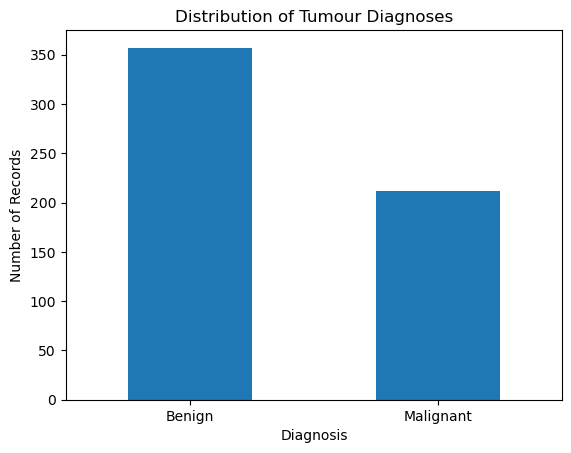

In [3]:
print("Diagnosis counts:")
print(df["Diagnosis"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

df["Diagnosis"].value_counts().rename(
    index={0: "Malignant", 1: "Benign"}
).plot(kind="bar", rot=0)

plt.title("Distribution of Tumour Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 455
Testing records: 114


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [6]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [7]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 98.25 %


Confusion Matrix:
[[41  1]
 [ 1 71]]


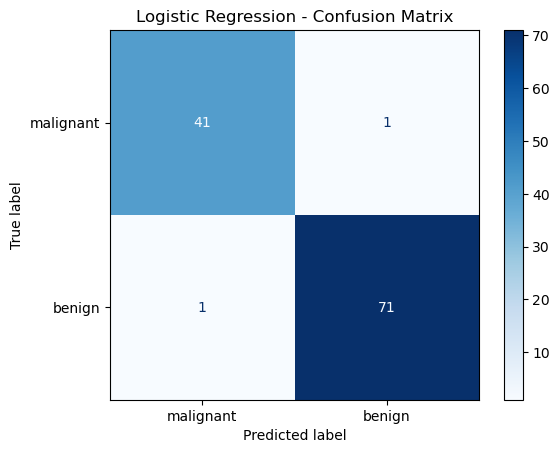

In [8]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [9]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Classification Report:

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



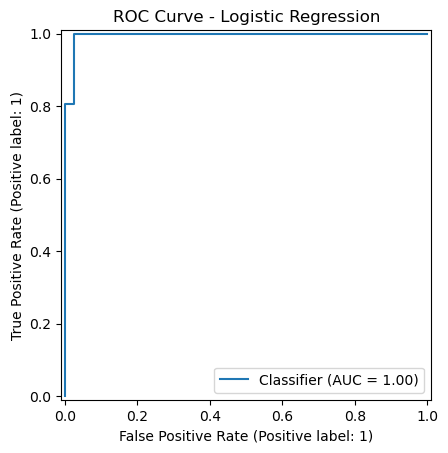

ROC-AUC Score: 0.9954


In [10]:
y_probability = model.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_probability)

RocCurveDisplay.from_predictions(y_test, y_probability)

plt.title("ROC Curve - Logistic Regression")
plt.show()

print("ROC-AUC Score:", round(auc, 4))

In [11]:
sample = X_test_scaled[0].reshape(1, -1)

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0]

print("Predicted Diagnosis:", data.target_names[prediction])
print("Actual Diagnosis:", data.target_names[y_test[0]])
print("Prediction Probability:", round(max(probability) * 100, 2), "%")

Predicted Diagnosis: malignant
Actual Diagnosis: malignant
Prediction Probability: 100.0 %
